In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\ARTHI SIVALINGAM\OneDrive\Desktop\heart-disease-mlops\.venv\Scripts\python.exe
3.12.9 (tags/v3.12.9:fdb8142, Feb  4 2025, 15:27:58) [MSC v.1942 64 bit (AMD64)]


In [2]:

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"
METADATA_FILE = PROJECT_ROOT / "data" / "raw" / "dataset_metadata.json"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "num",
]

df = pd.read_csv(
    RAW_FILE,
    header=None,
    names=COLUMNS,
    na_values=["?"],
    skipinitialspace=True,
)

metadata = json.loads(
    METADATA_FILE.read_text(encoding="utf-8")
)

print("Dataset shape:", df.shape)
print("Dataset source:", metadata["source_url"])
print("SHA-256:", metadata["sha256"])

display(df.head())


Matplotlib is building the font cache; this may take a moment.


Dataset shape: (303, 14)
Dataset source: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
SHA-256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:

print("=" * 55)
print("DATA QUALITY REPORT")
print("=" * 55)

print(f"\nNumber of records: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\nMissing values per column:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("missing_count").to_frame())

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nOriginal target distribution:")
display(
    df["num"].value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
)

print("\nDescriptive statistics:")
display(df.describe().T.round(2))


DATA QUALITY REPORT

Number of records: 303
Number of columns: 14
Duplicate rows: 0

Missing values per column:


,missing_count
ca,4
thal,2



Data types:


,data_type
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64



Original target distribution:


,count
num,
0,164
1,55
2,36
3,35
4,13



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


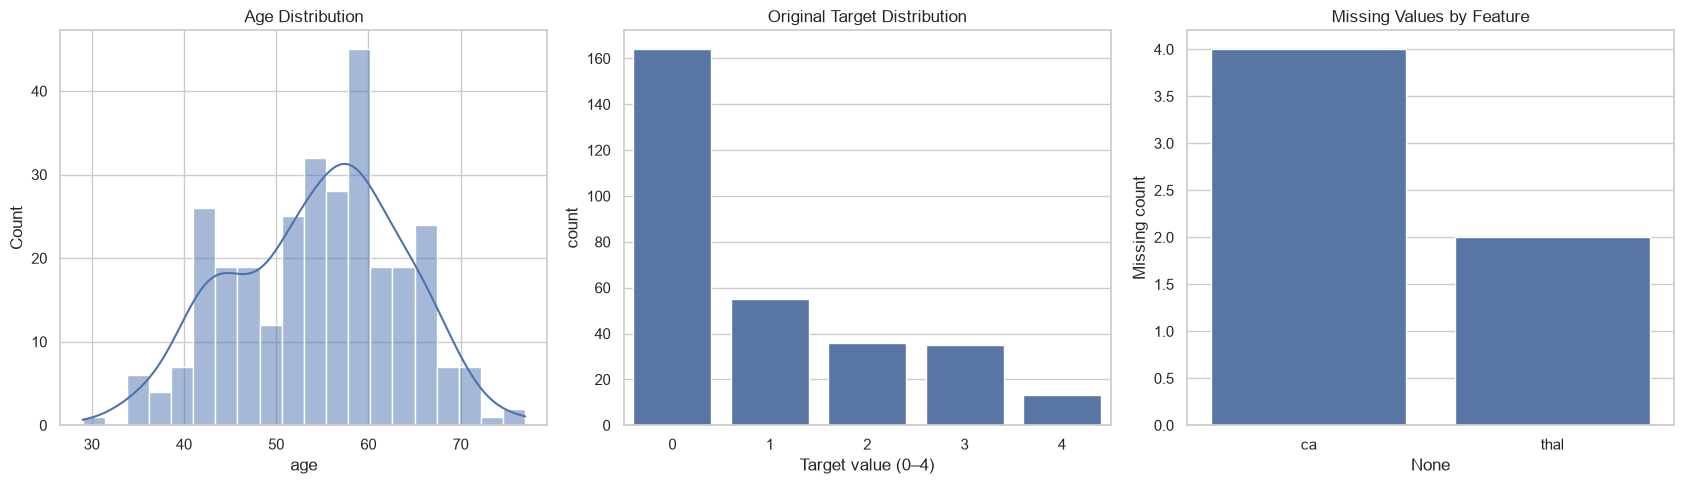

In [4]:

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Age distribution
sns.histplot(data=df, x="age", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

# 2. Original target distribution
sns.countplot(data=df, x="num", ax=axes[1])
axes[1].set_title("Original Target Distribution")
axes[1].set_xlabel("Target value (0–4)")

# 3. Missing-value counts
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

if not missing_counts.empty:
    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values,
        ax=axes[2],
    )
    axes[2].set_title("Missing Values by Feature")
    axes[2].set_ylabel("Missing count")
else:
    axes[2].text(0.5, 0.5, "No missing values",
                 ha="center", va="center")
    axes[2].set_title("Missing Values by Feature")

plt.tight_layout()
plt.show()


In [6]:
df_model = df.copy()

# 0 = no disease; 1–4 = disease present
df_model["target"] = (df_model["num"] > 0).astype("int64")

X = df_model.drop(columns=["num", "target"])
y = df_model["target"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

display(
    y.value_counts()
    .sort_index()
    .rename(index={0: "No disease", 1: "Disease present"})
    .rename("count")
    .to_frame()
)

assert X.shape == (303, 13)
assert len(y) == 303
assert y.nunique() == 2
assert not X.columns.isin(["num", "target"]).any()

print("Target definition and feature checks passed.")

Input feature shape: (303, 13)
Target shape: (303,)


,count
target,
No disease,164
Disease present,139


Target definition and feature checks passed.


In [7]:
from sklearn.model_selection import train_test_split

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test.value_counts().sort_index())

assert len(X_train) + len(X_test) == len(X)
assert len(y_train) == len(X_train)
assert len(y_test) == len(X_test)

print("\nTrain/test split validation passed.")

Training features: (242, 13)
Testing features: (61, 13)
Training targets: (242,)
Testing targets: (61,)

Training target distribution:


target
0    131
1    111
Name: count, dtype: int64


Testing target distribution:


target
0    33
1    28
Name: count, dtype: int64


Train/test split validation passed.


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

numeric_features = X_train.columns.tolist()

preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ]
)

# Fit only on training data; transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)S

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Missing values handled:", not np.isnan(X_train_processed).any())
print("Train/test preprocessing completed.")

Processed training shape: (242, 15)
Processed testing shape: (61, 15)
Missing values handled: True
Train/test preprocessing completed.


In [11]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
import pandas as pd

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", CalibratedClassifierCV(
            estimator=SVC(class_weight="balanced", random_state=42),
            cv=5,
            ensemble=False
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(3))
print("All three models trained successfully.")


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.918,0.871,0.964,0.915,0.961
1,SVM,0.803,0.722,0.929,0.812,0.929
2,Logistic Regression,0.803,0.722,0.929,0.812,0.916


All three models trained successfully.


In [12]:

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc",
        },
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean(),
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="CV ROC-AUC Mean",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(3))
print("5-fold cross-validation completed.")


,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV ROC-AUC Mean
0,Logistic Regression,0.826,0.017,0.801,0.897
1,Random Forest,0.793,0.013,0.769,0.886
2,SVM,0.822,0.028,0.800,0.885


5-fold cross-validation completed.
